# LEE classical experiments

In [58]:
import datetime
import os
import time

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from joblib import Parallel, delayed
from scipy import stats
from scipy.optimize import minimize, minimize_scalar

OUT_DIR = os.path.join("..", "output", "plots", "classic")
os.makedirs(OUT_DIR, exist_ok=True)

plt.style.use('default')

seed = datetime.datetime.now().microsecond+datetime.datetime.now().second+datetime.datetime.now().minute  # noqa: DTZ005
np.random.seed(seed)
print('Random seed:'+str(seed))

# ----------------------------------------------------------------------
# "Paper-like" style settings
# ----------------------------------------------------------------------
mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "mathtext.fontset": "cm",
})

# Common axes margins (figure fractions) for figures placed side by side in the paper
FIG_MARGINS = dict(left=0.15, right=0.97, top=0.97, bottom=0.13)

Random seed:601603


## 1. Classical bump hunt

A simplified bump-hunt: a smooth background with a possible narrow signal on top, as in a search for a new resonance in a mass spectrum.

- **Background:** smoothly falling continuum, truncated exponential on $[x_{\min}, x_{\max}]$:

$$
f_{\text{bkg}}(x \mid \lambda) = \frac{\lambda\, e^{-\lambda x}}{e^{-\lambda x_{\min}} - e^{-\lambda x_{\max}}}
$$

- **Signal:** a resonance at mass $m$ and width $\sigma$, truncated Gaussian:

$$
f_{\text{sig}}(x \mid m, \sigma) = \frac{\mathcal{N}(x \mid m, \sigma)}{\Phi\!\left(\frac{x_{\max}-m}{\sigma}\right) - \Phi\!\left(\frac{x_{\min}-m}{\sigma}\right)}
$$

- **Mixture model:** signal fraction $\mu$ is the fraction of events from the resonance:

$$
f(x \mid \lambda, m, \mu) = (1-\mu)\,f_{\text{bkg}}(x \mid \lambda) + \mu\,f_{\text{sig}}(x \mid m, \sigma)
$$

**From PDF to pseudodata.** Expected count per bin (width $\Delta x$, $N_{\text{tot}}$ total events):

$$
\nu_i \approx N_{\text{tot}}\, f(x_i^{\text{center}})\, \Delta x
$$

Observed counts are a Poisson realization of this expectation, mimicking one run of the experiment:

$$
n_i \sim \text{Poisson}(\nu_i)
$$

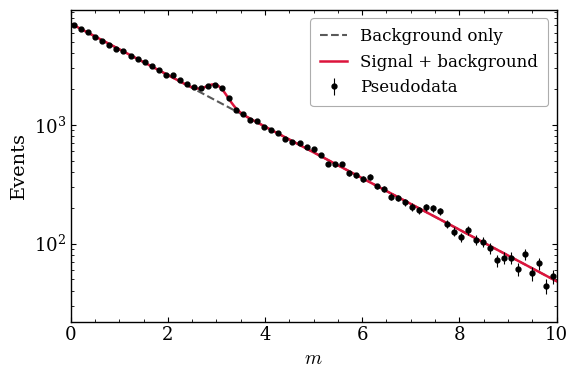

In [59]:
XMIN, XMAX = 0.0, 10.0
SIGMA_SIG = 0.2  # fixed signal width
M_SIG = 3.0      # fixed signal mean
MU_SIG = 0.02   # fixed signal fraction
LAM = 0.5         # fixed background decay rate

def bkg_pdf(x, lam):
    """Truncated exponential pdf on [XMIN, XMAX]."""
    norm = (np.exp(-lam * XMIN) - np.exp(-lam * XMAX))/lam
    return np.exp(-lam * x) / norm

def sig_pdf(x, m, sigma=SIGMA_SIG):
    """Truncated Gaussian pdf on [XMIN, XMAX]."""
    norm = stats.norm.cdf(XMAX, m, sigma) - stats.norm.cdf(XMIN, m, sigma)
    return stats.norm.pdf(x, m, sigma) / max(norm, 1e-12)

def expected_counts(lam, m, mu, edges, n_tot, width=SIGMA_SIG):
    centers = 0.5 * (edges[:-1] + edges[1:])
    widths = np.diff(edges)
    pdf_vals = (1 - mu) * bkg_pdf(centers, lam) + mu * sig_pdf(centers, m, sigma=width)
    return n_tot * pdf_vals * widths

def Z_from_mu(mu, n_tot, lam, m, width=SIGMA_SIG):
        """ Compute the significance Z for a given signal fraction mu. """
        x_low = m - 3 * width
        x_high = m + 3 * width
        N_sig = mu * n_tot * np.trapezoid(sig_pdf(np.linspace(x_low, x_high, 1000), m, width), np.linspace(x_low, x_high, 1000))
        N_bkg = (1 - mu) * n_tot * np.trapezoid(bkg_pdf(np.linspace(x_low, x_high, 1000), lam), np.linspace(x_low, x_high, 1000))
        if N_bkg <= 0:
            return 0.0
        return np.sqrt(N_sig**2 / N_bkg)

def mu_from_Z(z, n_tot, lam, m, width = SIGMA_SIG):
    """ Compute the signal fraction that corresponds to a given significance Z, for a given background and signal model. """

    # Use a root-finding method to find the signal fraction that gives the desired Z
    result = minimize_scalar(lambda mu: (Z_from_mu(mu, n_tot, lam, m, width) - z)**2, bounds=(0, 1), method='bounded')
    return result.x if result.success else None


# Histogram definitions
bins = np.linspace(XMIN, XMAX, 70)
centers = 0.5 * (bins[:-1] + bins[1:])
bin_width = np.diff(bins)[0]
N_events = 100000

# Poisson fluctuations to simulate observed counts
exp_counts = expected_counts(LAM, M_SIG, MU_SIG, bins, N_events)
data_counts = np.random.poisson(exp_counts)
data_err = np.sqrt(data_counts)


# Analytical curves for display (total, background-only)
x_plot = np.linspace(bins[0], bins[-1], 500)
pdf_total = (1 - MU_SIG) * bkg_pdf(x_plot, LAM) + MU_SIG * sig_pdf(x_plot, M_SIG)
pdf_bkg = (1 - MU_SIG) * bkg_pdf(x_plot, LAM)

scale = N_events * bin_width
pdf_total_scaled = pdf_total * scale
pdf_bkg_scaled = pdf_bkg * scale

# Plotting
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(centers, data_counts, yerr=data_err,fmt='o', ms=3.5, color='black', ecolor='black',elinewidth=0.8, capsize=0, label='Pseudodata', zorder=5)
ax.plot(x_plot, pdf_bkg_scaled, ls='--', lw=1.5, color='0.35', label='Background only')
ax.plot(x_plot, pdf_total_scaled, ls='-', lw=1.8, color='crimson',label='Signal + background')

ax.set_xlim(XMIN, XMAX)
ax.set_yscale('log')
ax.set_ylim(bottom=max(1, 0.5 * data_counts[data_counts > 0].min()))
ax.set_xlabel(r'$m$')
ax.set_ylabel('Events')

legend = ax.legend(frameon=True, loc='upper right', handlelength=1.6, borderpad=0.6)
legend.get_frame().set_edgecolor('0.6')
legend.get_frame().set_linewidth(0.8)
fig.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'pseudo_data.pdf'), dpi=300)
plt.show()

### 1.1 Null distribution of $q$ and $p$: fixed vs. scanned $m$

To quantify evidence for a resonance at a given mass $m$, we compare two nested hypotheses using a binned Poisson likelihood.

**Poisson likelihood.** For observed counts $n_i$ and expected counts $\nu_i(\boldsymbol{\theta})$, the log-likelihood (up to constants) is:

$$
-\ln \mathcal{L}(\boldsymbol{\theta}) = \sum_i \left( \nu_i(\boldsymbol{\theta}) - n_i \ln \nu_i(\boldsymbol{\theta}) \right)
$$

**Test statistic.** The profile likelihood ratio, evaluated at fixed $m$ (and $\sigma$):

$$
q(m) = 2 \left[ -\ln \mathcal{L}(\hat{\hat{\lambda}}, \mu{=}0) - \left(-\ln \mathcal{L}(\hat{\lambda}_m, m, \hat{\mu}_m)\right) \right], \qquad q(m) \geq 0
$$

Larger $q(m)$ means the data are better described by including a resonance at $m$. With $m$ and $\sigma$ fixed, $H_1$ has exactly one more free parameter than $H_0$ ($\mu$), so by Wilks' theorem:

$$
q(m) \big|_{H_0} \;\sim\; \chi^2_{1}\;\quad\quad\quad p(m)\big|_{H_0} \;\sim\mathrm{Uniform}(0,1)
$$

**Scanning over $m$.** Since we don't know in advance where a resonance might sit, we repeat the test at many mass points across $[x_{\min}, x_{\max}]$ on the *same* dataset and keep the largest value:

$$
q_{\max} = \max_{m} \; q(m)
$$

This is the look-elsewhere effect: scanning increases the chance of a large $q$ from a background fluctuation alone, so $q_{\max}$ is not $\chi^2_1$-distributed and the minimum $p$-value over the scan is not uniform. Below we compare both cases (fixed $m$ vs. scanned $m$) in the same figures.

In [60]:
# ----------------------------------------------------------------------
# Likelihood-ratio test statistic
# ----------------------------------------------------------------------
def nll(counts, expected):
    """Poisson negative log-likelihood (binned), dropping constant terms."""
    expected = np.clip(expected, 1e-9, None)
    return np.sum(expected - counts * np.log(expected))

def fit_bkg_only(counts, edges, n_tot):
    """Null hypothesis: pure exponential. Fit lambda, return (nll_min, lambda_hat)."""
    def obj(lam):
        return nll(counts, expected_counts(lam, 1.0, 0.0, edges, n_tot))
    res = minimize_scalar(obj, bounds=(0.01, 5.0), method="bounded")
    return res.fun, res.x

def fit_sig_plus_bkg(counts, edges, n_tot, m, lam_init, sigma=SIGMA_SIG):
    """Alternative hypothesis at fixed bump position m: profile signal fraction."""
    def obj(params):
        lam, mu = params
        return nll(counts, expected_counts(lam, m, mu, edges, n_tot, width=sigma))
    res = minimize(obj, x0=[lam_init, 0.0],bounds=[(0.01, 5.0), (0., 1.0)],method="L-BFGS-B",)
    lam_hat, mu_hat = res.x
    return res.fun, lam_hat, mu_hat

def likelihood_ratio_test(counts, edges, m, sigma=SIGMA_SIG):
    """
    Returns q = 2 * (NLL_null - NLL_alt) for a signal hypothesis at position m.
    Under Wilks' theorem, q ~ chi2(1) asymptotically (one extra free parameter: mu).
    """
    n_tot = counts.sum()
    nll_null, lam_hat_null = fit_bkg_only(counts, edges, n_tot)
    nll_alt, lam_hat_alt, mu_hat = fit_sig_plus_bkg(counts, edges, n_tot, m, lam_hat_null, sigma=sigma)
    q = 2.0 * (nll_null - nll_alt)
    return q, lam_hat_null, lam_hat_alt, mu_hat

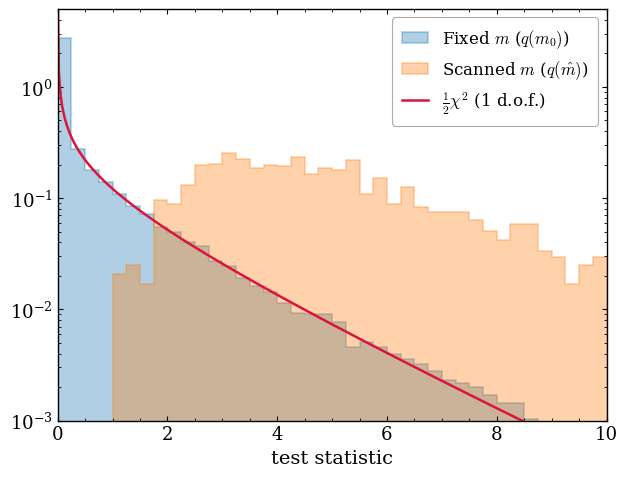

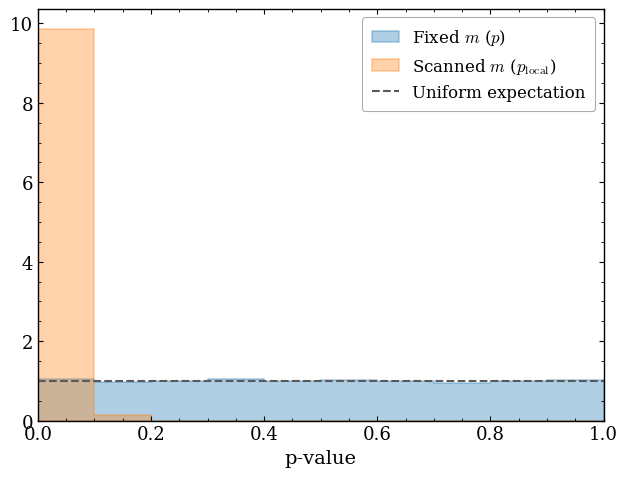

In [ ]:
# ----------------------------------------------------------------------
# Toy generation: fixed m
# ----------------------------------------------------------------------
N_calib_fixed = 50000  # toys used to calibrate the null dist of q (fixed m)
N_toys_fixed = 10000   # toys used to build the dist of local p-values

q_toys = []
for i in range(N_calib_fixed):
    toy_bkg = np.random.poisson(expected_counts(LAM, M_SIG, 0.0, bins, N_events))
    q, _ , lam_hat, mu_hat = likelihood_ratio_test(toy_bkg, bins, M_SIG)
    q_toys.append(q)
q_toys = np.array(q_toys)

p_dist = []
for i_toy in range(N_toys_fixed):
    toy_bkg_exp = np.random.poisson(expected_counts(LAM, 1.0, 0.0, bins, N_events))
    q_exp, _ , lam_hat, mu_hat = likelihood_ratio_test(toy_bkg_exp, bins, M_SIG)
    p_dist.append(np.sum(q_toys >= q_exp) / len(q_toys))
p_dist = np.array(p_dist)

# ----------------------------------------------------------------------
# Toy generation: scan over m
# ----------------------------------------------------------------------
N_calib_scan = 1000
N_toys_scan = 1000
m_grid = np.linspace(XMIN, XMAX, 300)

q_max_toys = []
for i in range(N_calib_scan):
    toy_bkg = np.random.poisson(expected_counts(LAM, M_SIG, 0.0, bins, N_events))
    q_m = [likelihood_ratio_test(toy_bkg, bins, m)[0] for m in m_grid]
    q_max_toys.append(np.max(q_m))
q_max_toys = np.array(q_max_toys)

p_global_dist = []
for i_toy in range(N_toys_scan):
    toy_bkg_exp = np.random.poisson(expected_counts(LAM, 1.0, 0.0, bins, N_events))
    p_m = []
    for m in m_grid:
        q_exp, _ , lam_hat, mu_hat = likelihood_ratio_test(toy_bkg_exp, bins, m)
        p_m.append(np.sum(q_toys >= q_exp) / len(q_toys))
    p_global_dist.append(min(p_m))  # global p-value is the minimum over m
p_global_dist = np.array(p_global_dist)

# ----------------------------------------------------------------------
# Plots
# ----------------------------------------------------------------------
def style_legend(leg):
    leg.get_frame().set_edgecolor('0.6')
    leg.get_frame().set_linewidth(0.8)

# 1) Test statistic distribution under the null hypothesis (background-only)
x_plot = np.linspace(0.001, 10, 500)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.hist(q_toys, bins=40, range=(0, 10), density=True, histtype='stepfilled', color='C0', alpha=0.35, edgecolor='C0', linewidth=1.2, label=r'Fixed $m$ ($q(m_0)$)')
ax.hist(q_max_toys, bins=40, range=(0, 10), density=True, histtype='stepfilled', color='C1', alpha=0.35, edgecolor='C1', linewidth=1.2, label=r'Scanned $m$ ($q(\hat{m})$)')
ax.plot(x_plot, 0.5*stats.chi2.pdf(x_plot, df=1), '-', color='crimson', lw=1.8, label=r'$\frac{1}{2}\chi^2$ (1 d.o.f.)')
ax.set_yscale('log')
ax.set_xlim(0, 10)
ax.set_ylim(1e-3, 5)
ax.set_xlabel(r'test statistic')
ax.tick_params(axis='x', pad=6)
style_legend(ax.legend(frameon=True, loc='upper right', handlelength=1.6, borderpad=0.6))
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'q_null_dist.pdf'), dpi=300)

# 2) Distribution of the p-values
fig2, ax2 = plt.subplots(figsize=(6.5, 5))
ax2.hist(p_dist, bins=10, range=(0, 1), density=True, histtype='stepfilled', color='C0', alpha=0.35, edgecolor='C0', linewidth=1.2, label=r'Fixed $m$ ($p$)')
ax2.hist(p_global_dist, bins=10, range=(0, 1), density=True, histtype='stepfilled', color='C1', alpha=0.35, edgecolor='C1', linewidth=1.2, label=r'Scanned $m$ ($p_{\mathrm{local}}$)')
ax2.axhline(1.0, ls='--', lw=1.5, color='0.35', label='Uniform expectation')
ax2.set_xlim(0, 1)
ax2.set_ylim(bottom=0)
ax2.set_xlabel(r'p-value')
ax2.tick_params(axis='x', pad=6)
style_legend(ax2.legend(frameon=True, loc='upper right', handlelength=1.6, borderpad=0.6))
fig2.tight_layout()
fig2.savefig(os.path.join(OUT_DIR, 'pval_dist.pdf'), dpi=300)

plt.show()

### 1.2 Gross & Vitells correction

Running enough toys to directly populate the far tail of $q_{\max}$ is expensive — a global p-value of $10^{-4}$ needs $\mathcal{O}(10^5\text{–}10^6)$ toys to resolve. Instead, we use the **Gross–Vitells** asymptotic method: estimate the trials factor cheaply at a *low* reference level $c_0$, then extrapolate to the *high* level $c$ we actually care about.

**Upcrossings.** For a single toy's scan $q(m)$, an upcrossing of level $c$ is a point where the curve rises from below $c$ to above $c$. Averaged over many background-only toys, this defines the expected upcrossing rate:

$$
\langle N(c) \rangle = \frac{1}{N_{\text{toys}}} \sum_{t} \big(\text{number of upcrossings of } c \text{ in toy } t\big)
$$

**Scaling law.** Under the asymptotic theory, the upcrossing rate falls off exponentially with level:

$$
\langle N(c) \rangle = \langle N(c_0) \rangle \, e^{-(c-c_0)/2}
$$

so $\langle N(c_0)\rangle$ measured cheaply at a *low* $c_0$ (where upcrossings are common and toys converge quickly) is enough to predict $\langle N(c)\rangle$ at any higher $c$, without ever having to observe a rare high-$c$ fluctuation directly.

**Global p-value.** Combining the local $\chi^2_1$ tail with the trials correction:

$$
p_{\text{global}}(c) \;\leq\; \frac{1}{2}P\!\left(\chi^2_1 > c\right) + \langle N(c) \rangle
$$

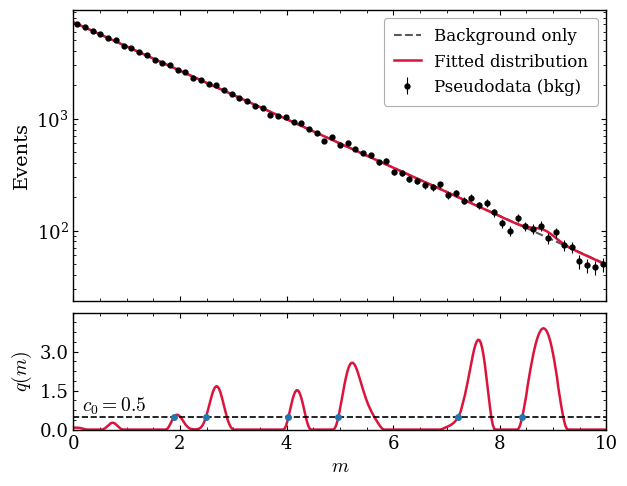

In [66]:
m_grid = np.linspace(XMIN, XMAX, 400)
toy_bkg_data = np.random.poisson(expected_counts(LAM, M_SIG, 0.0, bins, N_events))
toy_data_errors = np.sqrt(toy_bkg_data)

q_m = []
for m in m_grid:
    q, lam_hat_null, lam_hat_alt, mu_hat = likelihood_ratio_test(toy_bkg_data, bins, m)
    q_m.append([q, lam_hat_null, lam_hat_alt, mu_hat, m])
q_m = np.array(q_m)
lam_hat_bkg, lam_hat_sig, mu_hat, m_hat = q_m[np.argmax(q_m[:, 0]), 1:]

# Analytical curves for display (total, background-only)
x_plot = np.linspace(bins[0], bins[-1], 500)
pdf_total = (1 - mu_hat) * bkg_pdf(x_plot, lam_hat_sig) + mu_hat * sig_pdf(x_plot, m_hat)
pdf_bkg = bkg_pdf(x_plot, lam_hat_bkg)

scale = N_events * bin_width
pdf_total_scaled = pdf_total * scale
pdf_bkg_scaled = pdf_bkg * scale

#threshold = np.percentile(q_m[:, 0], 75)
threshold = 0.5
above = q_m[:, 0] > threshold
crossings = np.where(np.diff(above.astype(int)) > 0)[0]
# ----------------------------------------------------------------------
# Plots
# ----------------------------------------------------------------------
# 1) m scan and test statistic
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(6.5, 5), sharex=True,
    gridspec_kw={"height_ratios": [2.5, 1], "hspace": 0.06},
)

ax1.errorbar(centers, toy_bkg_data, yerr=toy_data_errors,fmt='o', ms=3.5, color='black', ecolor='black',elinewidth=0.8, capsize=0, label='Pseudodata (bkg)', zorder=5)
ax1.plot(x_plot, pdf_bkg_scaled, ls='--', lw=1.5, color='0.35', label='Background only')
ax1.plot(x_plot, pdf_total_scaled, ls='-', lw=1.8, color='crimson',label='Fitted distribution')
ax1.set_xlim(XMIN, XMAX)
ax1.set_yscale('log')
ax1.set_ylim(bottom=max(1, 0.5 * toy_bkg_data[toy_bkg_data > 0].min()))
ax1.set_ylabel('Events')
legend = ax1.legend(frameon=True, loc='upper right', handlelength=1.6, borderpad=0.6)
legend.get_frame().set_edgecolor('0.6')
legend.get_frame().set_linewidth(0.8)

ax2.plot(m_grid, q_m[:, 0], '-', color='crimson', lw=1.8)
ax2.axhline(threshold, ls='--', color='black', lw=1.2)
for c in crossings:
    ax2.plot(m_grid[c], threshold, 'o', color='C0', ms=4, zorder=5)
ax2.set_xlim(XMIN, XMAX)
ax2.set_ylim(0, max(q_m[:, 0].max() * 1.15, threshold * 4))
ax2.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=4))
ax2.annotate(rf'$c_0 = {threshold:g}$', xy=(0, threshold), xycoords=('axes fraction', 'data'),
             xytext=(6, 0.2), textcoords='offset points', ha='left', va='bottom', fontsize=14)
ax2.set_xlabel(r'$m$')
ax2.set_ylabel(r'$q(m)$')

fig.subplots_adjust(hspace=0.06, **FIG_MARGINS)
fig.savefig(os.path.join(OUT_DIR, 'mu_scan_upcrossings.pdf'), dpi=300)
plt.show()

In [8]:
def count_upcrossings(q_values, threshold):
    q_values = np.asarray(q_values)
    return np.sum(
        (q_values[:-1] < threshold) &
        (q_values[1:] >= threshold)
    )

def simulate_q_curve(seed, m_grid, bins, N_events):
    """
    Generate one background-only toy and evaluate q(m)
    over the complete m grid.
    """
    rng = np.random.default_rng(seed)
    mean_counts = expected_counts(LAM, 1.0, 0.0, bins, N_events)
    toy_bkg_exp = rng.poisson(mean_counts)
    q_values = np.empty(len(m_grid))
    for j, m in enumerate(m_grid):
        q_exp, lam_hat_null, lam_hat_alt, mu_hat = likelihood_ratio_test(toy_bkg_exp, bins, m)
        q_values[j] = q_exp

    return q_values


In [ ]:
N_toys = 100000
N_calib = 10000
N_low = 5000
m_grid = np.linspace(XMIN, XMAX, 350)
n_jobs = max(1, os.cpu_count() - 2)


# GV procedure to compute the trial factor for high c
seed_sequence = np.random.SeedSequence(12345)
low_seeds = [int(s.generate_state(1)[0]) for s in seed_sequence.spawn(N_low)]
q_curves_low = Parallel(
    n_jobs=n_jobs,
    backend="loky",
    verbose=1,
)( delayed(simulate_q_curve)(
        seed,
        m_grid,
        bins,
        N_events
    )
    for seed in low_seeds
)

Nc_low = np.array([count_upcrossings(q_values, 0.5) for q_values in q_curves_low])
Nc_extrpol = (np.mean(Nc_low)* np.exp(-(10.0 - 0.5) / 2.0))
Nc_extrpol_std = (np.std(Nc_low) / np.sqrt(len(Nc_low))) * np.exp(-(10.0 - 0.5) / 2.0)
local_tail = 0.5*stats.chi2.sf(10.0, df=1)
trial_GVextrpol = 1.0 + Nc_extrpol / local_tail
trial_GVextrpol_std = Nc_extrpol_std / local_tail

# Experimental computation of the trial factor for high c
seed_sequence = np.random.SeedSequence(54321)
high_seeds = [int(s.generate_state(1)[0]) for s in seed_sequence.spawn(N_toys)]
q_curves_high = Parallel(
    n_jobs=n_jobs,
    backend="loky",
    verbose=1,
    batch_size="auto"
)(
    delayed(simulate_q_curve)(
        seed,
        m_grid,
        bins,
        N_events
    )
    for seed in high_seeds
)
Nc = np.array([count_upcrossings(q_values, 10.0) for q_values in q_curves_high])
Nc_exp = np.mean(Nc)
Nc_exp_std = np.std(Nc) / np.sqrt(len(Nc))
trial_GVexp = 1.0 + Nc_exp / local_tail
trial_GVexp_std = Nc_exp_std / local_tail

# Experimental computation of the test statistic distribution
seed_sequence = np.random.SeedSequence(98765)
calib_seeds = [int(s.generate_state(1)[0]) for s in seed_sequence.spawn(N_calib)]
q_curves_calib = Parallel(
    n_jobs=n_jobs,
    backend="loky",
    verbose=1,
    batch_size="auto"
)(
    delayed(simulate_q_curve)(
        seed,
        m_grid,
        bins,
        N_events
    )
    for seed in calib_seeds
)
q_cal = np.array([np.max(q_values)for q_values in q_curves_calib])
n_exceed = np.count_nonzero(q_cal >= 10.0)
n_exceed_std = np.sqrt(n_exceed * (1 - n_exceed / N_calib))
trial_exp = n_exceed / N_calib / local_tail
trial_exp_std = n_exceed_std / N_calib / local_tail

print(f"Trial factor for high c (GV): {trial_GVexp:.2f} ± {trial_GVexp_std:.2f}")
print(f"Trial factor for high c (GV extrapolated): {trial_GVextrpol:.2f} ± {trial_GVextrpol_std:.2f}")
print(f"Trial factor for high c (experimental): {trial_exp:.2f} ± {trial_exp_std:.2f}")
print(f"Exceedances: {n_exceed}/{N_calib}")

[Parallel(n_jobs=26)]: Using backend LokyBackend with 26 concurrent workers.
[Parallel(n_jobs=26)]: Done 110 tasks      | elapsed:   22.4s
[Parallel(n_jobs=26)]: Done 313 tasks      | elapsed:   55.0s
[Parallel(n_jobs=26)]: Done 596 tasks      | elapsed:  1.7min
[Parallel(n_jobs=26)]: Done 961 tasks      | elapsed:  2.8min
[Parallel(n_jobs=26)]: Done 1406 tasks      | elapsed:  4.1min
[Parallel(n_jobs=26)]: Done 1933 tasks      | elapsed:  5.6min
[Parallel(n_jobs=26)]: Done 2540 tasks      | elapsed:  7.3min
[Parallel(n_jobs=26)]: Done 3229 tasks      | elapsed:  9.3min
[Parallel(n_jobs=26)]: Done 3998 tasks      | elapsed: 11.5min
[Parallel(n_jobs=26)]: Done 4849 tasks      | elapsed: 13.9min
[Parallel(n_jobs=26)]: Done 5000 out of 5000 | elapsed: 14.3min finished
[Parallel(n_jobs=26)]: Using backend LokyBackend with 26 concurrent workers.
[Parallel(n_jobs=26)]: Done 110 tasks      | elapsed:   21.7s
[Parallel(n_jobs=26)]: Done 313 tasks      | elapsed:   55.5s
[Parallel(n_jobs=26)]: 

Trial factor for high c (GV): 51.25 ± 0.79
Trial factor for high c (GV extrapolated): 52.01 ± 0.18
Trial factor for high c (experimental): 53.28 ± 2.55
Exceedances: 417/10000


[Parallel(n_jobs=26)]: Done 10000 out of 10000 | elapsed: 28.7min finished


### 1.3 Gross-Vitells vs Bonferroni correction

To see the pathology of a naive trials correction, we vary only the **density of the mass scan**, $N$, at fixed scan range $[x_{\min}, x_{\max}]$, and compare two ways of converting a local p-value into a global one.

- **Bonferroni.** Treats the $N$ scanned mass points as independent tests:

    $$
    p_{\text{global}}^{\text{Bonf}} = N \cdot p_{\text{local}} \quad\Longrightarrow\quad \text{trials factor} = N
    $$

    By construction this grows linearly and without bound as the grid is refined — even though refining the grid adds no new physical information once the spacing is finer than the signal width $\sigma$.

- **Gross–Vitells.** Estimates the *effective* number of independent trials from the upcrossing rate of $q(m)$ at a low, cheaply-populated level $c_0$, then extrapolates to the high level $c$ of interest:

    $$
    \langle N(c) \rangle = \langle N(c_0) \rangle \, e^{-(c - c_0)/2}, \qquad
    \frac{p_{\text{global}}}{p_{\text{local}}} \approx 1 + 2\cdot\frac{\langle N(c) \rangle}{P(\chi^2_1 > c)}
    $$

    Because $\langle N(c_0)\rangle$ is a property of the continuum curve $q(m)$, not of how many points we happened to sample it at, this trials factor should **converge** once the grid is fine enough to resolve the correlation length $\sim\sigma$, unlike Bonferroni.

In [ ]:
N_points = np.arange(11,200,10)
N_TOYS_GV = {0.5: 100, 7.5: 10000}   # c0 -> toys por cada valor de N
C0_LIST = list(N_TOYS_GV)
U_TARGET = 10.            # umbral u al que se extrapola
n_jobs = max(1, os.cpu_count() - 2)
local_tail = 0.5*stats.chi2.sf(U_TARGET, df=1)

trial_gv = {c0: [] for c0 in C0_LIST}
trial_gv_std = {c0: [] for c0 in C0_LIST}
seed_sequences = np.random.SeedSequence(24680).spawn(len(N_points))
for ni, seed_sequence in zip(N_points, seed_sequences):
    m_grid_ni = np.linspace(XMIN, XMAX, ni)
    toy_seeds = [int(s.generate_state(1)[0]) for s in seed_sequence.spawn(max(N_TOYS_GV.values()))]
    q_curves = Parallel(
        n_jobs=n_jobs,
        backend="loky",
        verbose=0,
        batch_size="auto"
    )(
        delayed(simulate_q_curve)(
            seed,
            m_grid_ni,
            bins,
            N_events
        )
        for seed in toy_seeds
    )

    # Mismo escaneo, distintos niveles de referencia: cada c0 usa sus primeros N_TOYS_GV[c0] toys
    for c0 in C0_LIST:
        Nc = np.array([count_upcrossings(q_values, c0) for q_values in q_curves[:N_TOYS_GV[c0]]])
        extrpol = np.exp(-(U_TARGET - c0) / 2.0)
        trial_gv[c0].append(1.0 + np.mean(Nc) * extrpol / local_tail)
        trial_gv_std[c0].append((np.std(Nc) / np.sqrt(len(Nc))) * extrpol / local_tail)
    print(f"N={ni}: " + ", ".join(f"c0={c0:g} -> {trial_gv[c0][-1]:.2f} ± {trial_gv_std[c0][-1]:.2f}" for c0 in C0_LIST))

trial_gv = {c0: np.array(v) for c0, v in trial_gv.items()}
trial_gv_std = {c0: np.array(v) for c0, v in trial_gv_std.items()}

# ------------------------------------------------------------------------------------------
# Plots
# ------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.5, 5))

ax.plot(N_points, N_points, '--', color='0.35', lw=1.6, marker='s', ms=4,label='Bonferroni ($=N$)')
gv_styles = {0.5: dict(color='crimson', fmt='o-'), 7.5: dict(color='royalblue', fmt='^-')}
for c0 in C0_LIST:
    st = gv_styles.get(c0, dict(color=None, fmt='o-'))
    ax.errorbar(N_points, trial_gv[c0], yerr=trial_gv_std[c0], fmt=st['fmt'], ms=4.5, color=st['color'], ecolor=st['color'],
                elinewidth=0.9, capsize=2, lw=1.6, label=rf'Gross–Vitells ($c_0={c0:g}$)')
ax.set_xlabel(r'Number of scanned mass points, $N$')
ax.set_ylabel(r'Trials factor, $p_{\mathrm{global}}/p_{\mathrm{local}}$')
ax.set_yscale('log')
legend = ax.legend(frameon=True, loc='upper left', handlelength=1.8, borderpad=0.6)
legend.get_frame().set_edgecolor('0.6')
legend.get_frame().set_linewidth(0.8)
fig.subplots_adjust(**FIG_MARGINS)
fig.savefig(os.path.join(OUT_DIR, 'trial_factor_Gv_Bon.pdf'), dpi=300)
plt.show()

N=11: c0=0.5 -> 22.44 ± 0.92, c0=7.5 -> 12.97 ± 0.65
N=21: c0=0.5 -> 38.91 ± 1.11, c0=7.5 -> 22.05 ± 0.86
N=31: c0=0.5 -> 46.32 ± 1.22, c0=7.5 -> 32.15 ± 1.05
N=41: c0=0.5 -> 47.76 ± 1.16, c0=7.5 -> 37.82 ± 1.14
N=51: c0=0.5 -> 47.98 ± 1.32, c0=7.5 -> 41.05 ± 1.18
N=61: c0=0.5 -> 52.40 ± 1.35, c0=7.5 -> 47.12 ± 1.26
N=71: c0=0.5 -> 52.73 ± 1.35, c0=7.5 -> 47.49 ± 1.28
N=81: c0=0.5 -> 52.07 ± 1.46, c0=7.5 -> 47.85 ± 1.26
N=91: c0=0.5 -> 50.96 ± 1.31, c0=7.5 -> 47.49 ± 1.28
N=101: c0=0.5 -> 51.74 ± 1.34, c0=7.5 -> 48.00 ± 1.28
N=111: c0=0.5 -> 52.07 ± 1.20, c0=7.5 -> 50.38 ± 1.29


### 1.4 The dependence on the signal template width

$\sigma$ sets the correlation length of $q(m)$: broader templates $\Rightarrow$ slower-varying $q(m)$ $\Rightarrow$ fewer independent excursions above $c_0$ over the same range:

$$
\sigma \uparrow \quad\Longrightarrow\quad \langle N(c_0) \rangle \downarrow \quad\Longrightarrow\quad \frac{p_{\text{global}}}{p_{\text{local}}} \downarrow
$$

i.e. a narrow signal hypothesis is penalized more than a broad one, at fixed scan range and grid density, the trials factor depends on the signal shape being tested, not just on $N$.

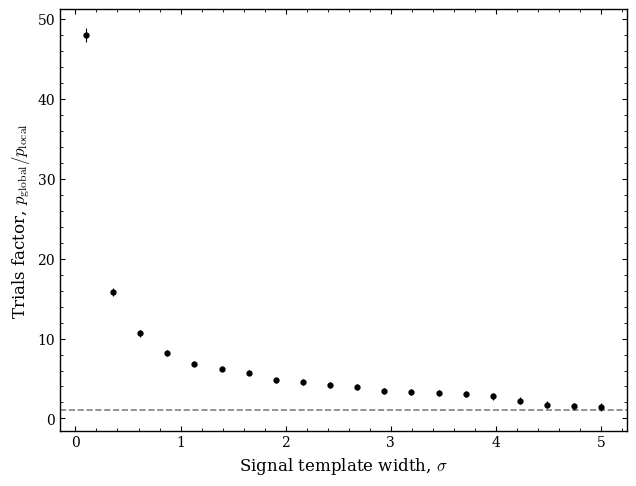

In [8]:
m_grid = np.linspace(XMIN, XMAX, 100)

trial_gv = []
trial_gv_std = []
sig_sigma_grid = np.linspace(0.1, 5, 20)
Nc = { sigma: [] for sigma in sig_sigma_grid }
Nc_extrapol = { sigma: 0 for sigma in sig_sigma_grid }

for i_toy in range(100):
    toy_bkg_exp = np.random.poisson(expected_counts(LAM, 1.0, 0.0, bins, N_events))
    for sigma in sig_sigma_grid:
        q_m = []
        for m in m_grid:
            q_exp, lam_hat_null, lam_hat_alt, mu_hat = likelihood_ratio_test(toy_bkg_exp, bins, m, sigma=sigma)
            q_m.append([q_exp, lam_hat_null, lam_hat_alt, mu_hat, m])
        q_m = np.array(q_m)

        Nc[sigma].append(count_upcrossings(q_m[:, 0], 0.5))
for sigma in sig_sigma_grid:
    Nc[sigma] = np.array(Nc[sigma])
    Nc_extrapol[sigma] = np.mean(Nc[sigma])*np.exp(-(10.-0.5)/2)
    trial_gv.append(1.+Nc_extrapol[sigma]/stats.chi2.sf(10., df=1))
    trial_gv_std.append((Nc[sigma].std() / max(Nc[sigma].mean(), 1e-9)) * trial_gv[-1] / np.sqrt(len(m_grid)))

trial_gv = np.array(trial_gv)
trial_gv_std = np.array(trial_gv_std)

# ------------------------------------------------------------------------------------------
# Plots
# ------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.axhline(1., ls='--', color='gray', lw=1.2)
ax.errorbar(sig_sigma_grid, trial_gv, yerr=trial_gv_std, fmt='o', ms=3.5, color='black', ecolor='black',elinewidth=0.8, capsize=0)
ax.set_xlabel(r'Signal template width, $\sigma$')
ax.set_ylabel(r'Trials factor, $p_{\mathrm{global}}/p_{\mathrm{local}}$')
#ax.set_yscale('log')
legend.get_frame().set_edgecolor('0.6')
legend.get_frame().set_linewidth(0.8)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'tfactor_vs_signalwidth.pdf'), dpi=300)
plt.show()

## 2. Multi-channel search

### 2.1. Particle decay channels

In [9]:
N_TOYS = 5000
XMIN, XMAX = 0.0, 10.0
LAM_RANGE = np.linspace(0.1, 0.5, 11)  # different background decay rate
N_CHANNELS = 6  # number of channels
M_INJ = 2.5  # fixed signal position
CONFIG_SEED = 2468  # seed for the channel configuration (widths, backgrounds, signal channels and strengths)
rng_config = np.random.default_rng(CONFIG_SEED)
SIGMA_CH = rng_config.uniform(0.2, 0.5, size=N_CHANNELS)  # signal template width used in the scan of each channel
LAM_CH = rng_config.choice(LAM_RANGE, size=N_CHANNELS)
print(f"Signal widths for each channel: {SIGMA_CH}")
print(f"Background decay rates for each channel: {LAM_CH}")
sig_channels = rng_config.choice(N_CHANNELS, size=3, replace=False)  # channels with signal
bkg_mask = np.ones(N_CHANNELS, dtype=bool)
bkg_mask[sig_channels] = False

m_scan = np.linspace(XMIN, XMAX, 200)
N_GV_TOYS = 800
C0 = 0.5  # GV reference level
n_jobs = max(1, os.cpu_count() - 2)

# Injected signal (fixed configuration across toys): fraction and true width per channel
Z_SIG = rng_config.uniform(2, 4, size=sig_channels.size)
MU_INJ = np.zeros(N_CHANNELS)
MU_INJ[sig_channels] = [mu_from_Z(z, N_events, lam, M_INJ, width=sigma) for z, lam, sigma in zip(Z_SIG, LAM_CH[sig_channels], SIGMA_CH[sig_channels])]
SIGMA_INJ = np.zeros(N_CHANNELS)
SIGMA_INJ = SIGMA_CH  # true width of the injected signal is the same as the scan width for each channel
print(f"Signal channels: {sig_channels}, Z_SIG={Z_SIG}, mu={MU_INJ[sig_channels]}, sigma_inj={SIGMA_INJ[sig_channels]}")

# ------------------------------------------------------------
# Toy workers
# ------------------------------------------------------------
def scan_q(counts, m_grid, edges, sigma):
    """q(m) over the grid. The background-only fit does not depend on m, so it is done once."""
    n_tot = counts.sum()
    nll_null, lam_hat_null = fit_bkg_only(counts, edges, n_tot)
    q_values = np.empty(len(m_grid))
    mu_hats = np.empty(len(m_grid))
    for j, m in enumerate(m_grid):
        nll_alt, _, mu_hats[j] = fit_sig_plus_bkg(counts, edges, n_tot, m, lam_hat_null, sigma=sigma)
        q_values[j] = 2.0 * (nll_null - nll_alt)
    return q_values, mu_hats

def simulate_channel_toy(seed, lam, sigma_scan, m_grid, edges, n_events, mu_inj=0.0, m_inj=0.0, sigma_inj=0.0):
    """One pseudo-experiment of one channel (signal injected if mu_inj > 0). Returns (q_max, m_hat, mu_hat)."""
    rng = np.random.default_rng(seed)
    n_sig = rng.poisson(n_events * mu_inj) if mu_inj > 0 else 0
    counts = rng.poisson(expected_counts(lam, 1.0, 0.0, edges, n_events - n_sig))
    if n_sig > 0:
        counts = counts + np.histogram(rng.normal(m_inj, sigma_inj, size=n_sig), bins=edges)[0]
    q_values, mu_hats = scan_q(counts, m_grid, edges, sigma_scan)
    i_max = np.argmax(q_values)
    return max(q_values[i_max], 0.0), m_grid[i_max], mu_hats[i_max]

def simulate_null_upcrossings(seed, lam, sigma_scan, m_grid, edges, n_events, c0):
    """Background-only toy for the GV calibration: number of upcrossings of q(m) above c0."""
    rng = np.random.default_rng(seed)
    counts = rng.poisson(expected_counts(lam, 1.0, 0.0, edges, n_events))
    q_values, _ = scan_q(counts, m_grid, edges, sigma_scan)
    return count_upcrossings(q_values, c0)

# ------------------------------------------------------------
# Toys: q_max for each channel and pseudo-experiment
# ------------------------------------------------------------
seed_sequence = np.random.SeedSequence([CONFIG_SEED, 13579])
toy_seeds = [int(s.generate_state(1)[0]) for s in seed_sequence.spawn(N_CHANNELS * N_TOYS)]
toy_results = Parallel(n_jobs=n_jobs, backend="loky", verbose=1, batch_size="auto")(
    delayed(simulate_channel_toy)(
        toy_seeds[channel * N_TOYS + i_toy],
        LAM_CH[channel],
        SIGMA_CH[channel],
        m_scan,
        bins,
        N_events,
        MU_INJ[channel],
        M_INJ,
        SIGMA_INJ[channel]
    )
    for channel in range(N_CHANNELS) for i_toy in range(N_TOYS)
)
toy_results = np.array(toy_results).reshape(N_CHANNELS, N_TOYS, 3).transpose(1, 0, 2)  # (N_TOYS, N_CHANNELS, 3)
q_max_toys, m_hat_toys, mu_hat_toys = toy_results[..., 0], toy_results[..., 1], toy_results[..., 2]

# ----------------------------------------------------------------------------
# GV calibration: <N(C0)> per channel (depends only on LAM_CH, SIGMA_CH and the grid)
# ----------------------------------------------------------------------------
seed_sequence = np.random.SeedSequence([CONFIG_SEED, 97531])
gv_seeds = [int(s.generate_state(1)[0]) for s in seed_sequence.spawn(N_CHANNELS * N_GV_TOYS)]
Nc_low = Parallel(n_jobs=n_jobs, backend="loky", verbose=1, batch_size="auto")(
    delayed(simulate_null_upcrossings)(
        gv_seeds[channel * N_GV_TOYS + i_toy],
        LAM_CH[channel],
        SIGMA_CH[channel],
        m_scan,
        bins,
        N_events,
        C0
    )
    for channel in range(N_CHANNELS) for i_toy in range(N_GV_TOYS)
)
Nc_low = np.array(Nc_low).reshape(N_CHANNELS, N_GV_TOYS)
Nc0 = Nc_low.mean(axis=1)
Nc0_err = Nc_low.std(axis=1) / np.sqrt(N_GV_TOYS)

# ----------------------------------------------------------------------------
# Local and global p-values, shape (N_TOYS, N_CHANNELS)
# ----------------------------------------------------------------------------
# q ~ 1/2 chi2_0 + 1/2 chi2_1 (mu >= 0): P(q >= c) = 1/2 chi2_1.sf(c) for c > 0 and 1 for c = 0
p_local_toys = np.where(q_max_toys > 0, 0.5 * stats.chi2.sf(q_max_toys, df=1), 1.0)
gv_extrapol = np.exp(-(q_max_toys - C0) / 2)
p_global_toys = np.clip(p_local_toys + Nc0 * gv_extrapol, None, 1.0)
p_global_toys_err = Nc0_err * gv_extrapol

for channel in range(N_CHANNELS):
    kind = 'signal' if not bkg_mask[channel] else 'bkg'
    print(f"Channel {channel+1} ({kind}): <N(C0)>={Nc0[channel]:.2f} ± {Nc0_err[channel]:.2f}, "
          f"median q_max={np.median(q_max_toys[:, channel]):.2f}, median p_global={np.median(p_global_toys[:, channel]):.3e}, "
          f"frac(q_max < C0)={np.mean(q_max_toys[:, channel] < C0):.3f}")

# Single pseudo-experiment for the plot in the next cell
p_global_chan = p_global_toys[0]

Signal widths for each channel: [0.32457914 0.38860848 0.47989288 0.39890442 0.22201837 0.46806733]
Background decay rates for each channel: [0.34 0.22 0.42 0.38 0.22 0.3 ]
Signal channels: [4 5 3], Z_SIG=[2.14608461 3.70354363 3.12687776], mu=[0.00296671 0.00768435 0.00603316], sigma_inj=[0.22201837 0.46806733 0.39890442]


[Parallel(n_jobs=26)]: Using backend LokyBackend with 26 concurrent workers.
[Parallel(n_jobs=26)]: Done 148 tasks      | elapsed:    9.0s
[Parallel(n_jobs=26)]: Done 398 tasks      | elapsed:   20.9s
[Parallel(n_jobs=26)]: Done 748 tasks      | elapsed:   37.3s
[Parallel(n_jobs=26)]: Done 1198 tasks      | elapsed:  1.0min
[Parallel(n_jobs=26)]: Done 1748 tasks      | elapsed:  1.5min
[Parallel(n_jobs=26)]: Done 2398 tasks      | elapsed:  2.1min
[Parallel(n_jobs=26)]: Done 3148 tasks      | elapsed:  2.8min
[Parallel(n_jobs=26)]: Done 3998 tasks      | elapsed:  3.6min
[Parallel(n_jobs=26)]: Done 4948 tasks      | elapsed:  4.5min
[Parallel(n_jobs=26)]: Done 5998 tasks      | elapsed:  5.4min
[Parallel(n_jobs=26)]: Done 7148 tasks      | elapsed:  6.4min
[Parallel(n_jobs=26)]: Done 8398 tasks      | elapsed:  7.5min
[Parallel(n_jobs=26)]: Done 9748 tasks      | elapsed:  8.8min
[Parallel(n_jobs=26)]: Done 11198 tasks      | elapsed: 10.1min
[Parallel(n_jobs=26)]: Done 12748 tasks    

Channel 1 (bkg): <N(C0)>=2.99 ± 0.03, median q_max=3.77, median p_global=6.091e-01, frac(q_max < C0)=0.000
Channel 2 (bkg): <N(C0)>=2.51 ± 0.03, median q_max=3.49, median p_global=5.939e-01, frac(q_max < C0)=0.001
Channel 3 (bkg): <N(C0)>=2.15 ± 0.03, median q_max=3.18, median p_global=5.990e-01, frac(q_max < C0)=0.002
Channel 4 (signal): <N(C0)>=2.47 ± 0.03, median q_max=14.49, median p_global=2.340e-03, frac(q_max < C0)=0.000
Channel 5 (signal): <N(C0)>=4.20 ± 0.04, median q_max=8.14, median p_global=9.439e-02, frac(q_max < C0)=0.000
Channel 6 (signal): <N(C0)>=2.13 ± 0.03, median q_max=18.67, median p_global=2.494e-04, frac(q_max < C0)=0.000


[Parallel(n_jobs=26)]: Done 4800 out of 4800 | elapsed:  4.5min finished


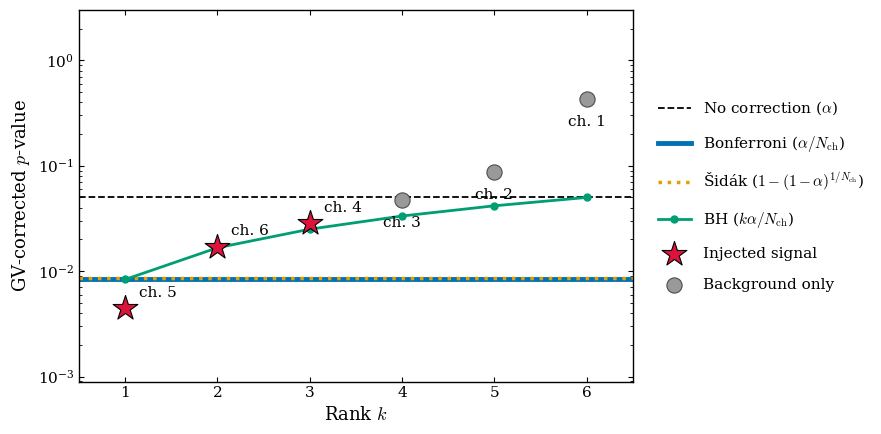

In [10]:
all_channels = np.arange(N_CHANNELS)
bkg_mask = np.ones(N_CHANNELS, dtype=bool)
bkg_mask[sig_channels] = False
p_global_chan = np.clip(np.array(p_global_chan), None, 1.0)
ALPHA = 0.05

# Rank channels by global p-value
p_global_argsorted = np.argsort(p_global_chan)
p_global_sorted = p_global_chan[p_global_argsorted]
ranks = np.arange(1, N_CHANNELS + 1)
is_sig_sorted = ~bkg_mask[p_global_argsorted]

# Thresholds on the global p-value
alpha_bonferroni = ALPHA / N_CHANNELS
alpha_sidak = 1 - (1 - ALPHA) ** (1 / N_CHANNELS)
bh_thresholds = ranks * ALPHA / N_CHANNELS  # FDR level of 5%

# ------------------------------------------------------------------------------------------
# Plot: all corrections in one figure
# ------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhline(ALPHA, color='black', ls='--', lw=1.3, label=r'No correction ($\alpha$)')
ax.axhline(alpha_bonferroni, color='#0072B2', ls='-', lw=3.5, label=r'Bonferroni ($\alpha/N_{\rm ch}$)')
ax.axhline(alpha_sidak, color='#E69F00', ls=':', lw=2.5, label=r'Šidák ($1-(1-\alpha)^{1/N_{\rm ch}}$)')
ax.plot(ranks, bh_thresholds, '-o', color='#009E73', lw=2, ms=5, label=r'BH ($k\alpha/N_{\rm ch}$)')

ax.scatter(ranks[is_sig_sorted], p_global_sorted[is_sig_sorted], s=350, marker='*', color='crimson', edgecolor='black', linewidth=0.8, zorder=5, label='Injected signal')
ax.scatter(ranks[~is_sig_sorted], p_global_sorted[~is_sig_sorted], s=120, marker='o', color='0.6', edgecolor='0.3', linewidth=0.8, zorder=5, label='Background only')

ax.set_yscale('log')
ax.set_xlim(0.5, N_CHANNELS + 0.5)
ax.set_ylim(min(p_global_sorted.min(), alpha_bonferroni) / 5, 3)
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
ax.tick_params(axis='x', which='minor', bottom=False, top=False)
ax.set_xlabel('Rank $k$')
ax.set_ylabel('GV-corrected $p$-value')
ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5), handlelength=2.2, labelspacing=1.1)
fig.tight_layout()

# Channel labels (only readable for a small number of channels): each label takes the first candidate
# position that stays inside the axes and does not overlap any line, marker or previously placed label
if N_CHANNELS <= 15:
    renderer = fig.canvas.get_renderer()
    line_paths = [line.get_transform().transform_path(line.get_path()) for line in ax.lines]
    pts_disp = ax.transData.transform(np.column_stack([ranks, p_global_sorted]))
    marker_r = np.where(is_sig_sorted, np.sqrt(350), np.sqrt(120)) / 2 * fig.dpi / 72  # marker radius in pixels
    marker_boxes = [mpl.transforms.Bbox.from_extents(x - r, y - r, x + r, y + r) for (x, y), r in zip(pts_disp, marker_r)]
    # (dx, dy) in points, ha, va: preferred positions first
    candidates_sig = [(10, 6, 'left', 'bottom'), (10, -6, 'left', 'top'), (-10, 6, 'right', 'bottom'), (-10, -6, 'right', 'top'),
                      (0, 14, 'center', 'bottom'), (0, -14, 'center', 'top')]
    candidates_bkg = [(0, -12, 'center', 'top'), (0, 12, 'center', 'bottom'), (10, -6, 'left', 'top'), (10, 6, 'left', 'bottom'),
                      (-10, -6, 'right', 'top'), (-10, 6, 'right', 'bottom')]
    candidates_far = [(dx * f, dy * f, ha, va) for f in (2, 3) for dx, dy, ha, va in candidates_sig]
    placed = []
    for i, (k, ch, p, is_sig) in enumerate(zip(ranks, p_global_argsorted, p_global_sorted, is_sig_sorted)):
        candidates = (candidates_sig if is_sig else candidates_bkg) + candidates_far
        for dx, dy, ha, va in candidates:
            ann = ax.annotate(f'ch. {ch + 1}', (k, p), xytext=(dx, dy), textcoords='offset points', ha=ha, va=va, fontsize=13)
            bbox = ann.get_window_extent(renderer).padded(2)
            free = (ax.bbox.contains(bbox.x0, bbox.y0) and ax.bbox.contains(bbox.x1, bbox.y1)
                    and not any(path.intersects_bbox(bbox, filled=False) for path in line_paths)
                    and not any(bbox.overlaps(b) for j, b in enumerate(marker_boxes) if j != i)
                    and not any(bbox.overlaps(b) for b in placed))
            if free:
                break
            ann.remove()
        else:  # no free position: fall back to the preferred one
            dx, dy, ha, va = candidates[0]
            ann = ax.annotate(f'ch. {ch + 1}', (k, p), xytext=(dx, dy), textcoords='offset points', ha=ha, va=va, fontsize=13)
        placed.append(ann.get_window_extent(renderer))

fig.savefig(os.path.join(OUT_DIR, 'multiple_testing_corrections.pdf'), dpi=300, bbox_inches='tight')

plt.show()

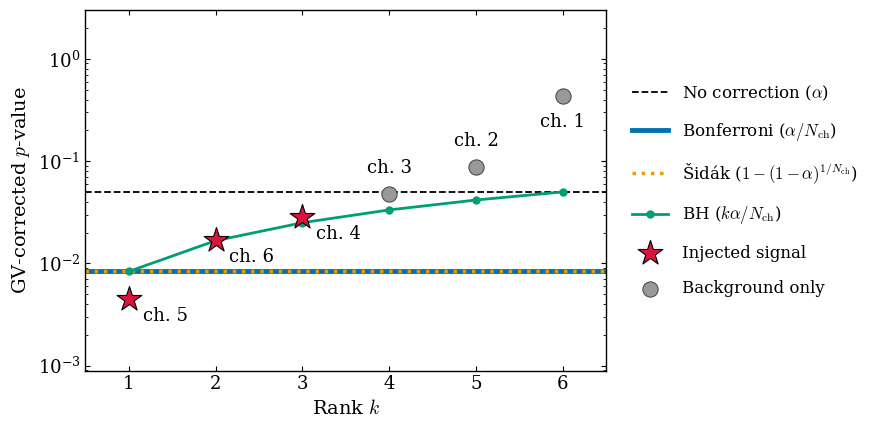

In [79]:
# ------------------------------------------------------------------------------------------
# Plot: all corrections in one figure
# ------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhline(ALPHA, color='black', ls='--', lw=1.3, label=r'No correction ($\alpha$)')
ax.axhline(alpha_bonferroni, color='#0072B2', ls='-', lw=3.5, label=r'Bonferroni ($\alpha/N_{\rm ch}$)')
ax.axhline(alpha_sidak, color='#E69F00', ls=':', lw=2.5, label=r'Šidák ($1-(1-\alpha)^{1/N_{\rm ch}}$)')
ax.plot(ranks, bh_thresholds, '-o', color='#009E73', lw=2, ms=5, label=r'BH ($k\alpha/N_{\rm ch}$)')

ax.scatter(ranks[is_sig_sorted], p_global_sorted[is_sig_sorted], s=350, marker='*', color='crimson', edgecolor='black', linewidth=0.8, zorder=5, label='Injected signal')
ax.scatter(ranks[~is_sig_sorted], p_global_sorted[~is_sig_sorted], s=120, marker='o', color='0.6', edgecolor='0.3', linewidth=0.8, zorder=5, label='Background only')

ax.set_yscale('log')
ax.set_xlim(0.5, N_CHANNELS + 0.5)
ax.set_ylim(min(p_global_sorted.min(), alpha_bonferroni) / 5, 3)
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
ax.tick_params(axis='x', which='minor', bottom=False, top=False)
ax.set_xlabel('Rank $k$')
ax.set_ylabel('GV-corrected $p$-value')
ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5), handlelength=2.2, labelspacing=1.1)
fig.tight_layout()

# Channel labels (only readable for a small number of channels): each label takes the first candidate
# position that stays inside the axes and does not overlap any line, marker or previously placed label
if N_CHANNELS <= 15:
    renderer = fig.canvas.get_renderer()
    line_paths = [line.get_transform().transform_path(line.get_path()) for line in ax.lines]
    pts_disp = ax.transData.transform(np.column_stack([ranks, p_global_sorted]))
    marker_r = np.where(is_sig_sorted, np.sqrt(350), np.sqrt(120)) / 2 * fig.dpi / 72  # marker radius in pixels
    marker_boxes = [mpl.transforms.Bbox.from_extents(x - r, y - r, x + r, y + r) for (x, y), r in zip(pts_disp, marker_r)]
    # (dx, dy) in points, ha, va: preferred positions first
    candidates_sig = [(10, 6, 'left', 'bottom'), (10, -6, 'left', 'top'), (-10, 6, 'right', 'bottom'), (-10, -6, 'right', 'top'),
                      (0, 14, 'center', 'bottom'), (0, -14, 'center', 'top')]
    candidates_bkg = [(0, -12, 'center', 'top'), (0, 12, 'center', 'bottom'), (10, -6, 'left', 'top'), (10, 6, 'left', 'bottom'),
                      (-10, -6, 'right', 'top'), (-10, 6, 'right', 'bottom')]
    candidates_far = [(dx * f, dy * f, ha, va) for f in (2, 3) for dx, dy, ha, va in candidates_sig]
    placed = []
    for i, (k, ch, p, is_sig) in enumerate(zip(ranks, p_global_argsorted, p_global_sorted, is_sig_sorted)):
        candidates = (candidates_sig if is_sig else candidates_bkg) + candidates_far
        for dx, dy, ha, va in candidates:
            ann = ax.annotate(f'ch. {ch + 1}', (k, p), xytext=(dx, dy), textcoords='offset points', ha=ha, va=va, fontsize=13)
            bbox = ann.get_window_extent(renderer).padded(2)
            free = (ax.bbox.contains(bbox.x0, bbox.y0) and ax.bbox.contains(bbox.x1, bbox.y1)
                    and not any(path.intersects_bbox(bbox, filled=False) for path in line_paths)
                    and not any(bbox.overlaps(b) for j, b in enumerate(marker_boxes) if j != i)
                    and not any(bbox.overlaps(b) for b in placed))
            if free:
                break
            ann.remove()
        else:  # no free position: fall back to the preferred one
            dx, dy, ha, va = candidates[0]
            ann = ax.annotate(f'ch. {ch + 1}', (k, p), xytext=(dx, dy), textcoords='offset points', ha=ha, va=va, fontsize=13)
        placed.append(ann.get_window_extent(renderer))

fig.savefig(os.path.join(OUT_DIR, 'multiple_testing_corrections.pdf'), dpi=300, bbox_inches='tight')

plt.show()

### 2.2 Unknown physics process

In [ ]:
XMIN, XMAX = 0.0, 10.0
LAM_RANGE = np.linspace(0.1, 0.5, 11)  # different background decay rate
N_CHANNELS = 50  # number of channels
SIGMA_SIG = 0.3  # fixed signal width
sig_channels = np.random.choice(range(50), size=10, replace=False)  # channels with signal
print(f"Channels with signal: {sig_channels}")

m_grid = np.linspace(XMIN, XMAX, 100)
# ------------------------------------------------------------
# Local p-value for each channel
# ------------------------------------------------------------
p_local_chan = []
# Bckground-only channels
for channel in range(N_CHANNELS - sig_channels.size):
    LAM = np.random.choice(LAM_RANGE)
    M_SIG = np.random.uniform(0.5, 9.5)
    toy_bck_exp = np.random.poisson(expected_counts(LAM, 1.0, 0.0, bins, N_events))
    q_m_exp = []
    for m in m_grid:
            q_exp, lam_hat_null, lam_hat_alt, mu_hat = likelihood_ratio_test(toy_bck_exp, bins, m, sigma=SIGMA_SIG)
            q_m_exp.append([q_exp, lam_hat_null, lam_hat_alt, mu_hat, m])
    q_m_val, m_hat = q_m_exp[np.argmax(np.array(q_m_exp)[:, 0])][0], q_m_exp[np.argmax(np.array(q_m_exp)[:, 0])][-1]
    p_local_chan.append(stats.chi2.sf(q_m_val, df=1))

# Signal channels
sigmas_sig = np.full(sig_channels.size, SIGMA_SIG)  # fixed signal width
rho = 0.6
corr = np.full((sig_channels.size, sig_channels.size), rho)

np.fill_diagonal(corr, 1.0)
LAM = np.random.choice(LAM_RANGE, size=sig_channels.size)
M_SIG = np.random.uniform(0.5, 9.5, size=sig_channels.size)
COV_SIG = np.diag(sigmas_sig) @ corr @ np.diag(sigmas_sig)
Z_SIG = np.random.uniform(3.5, 5.5, size=sig_channels.size)
mu = [mu_from_Z(z, N_events, lam, m) for z, lam, m in zip(Z_SIG, LAM, M_SIG)]

sig_multichan_events = stats.multivariate_normal.rvs(mean=M_SIG,cov=COV_SIG,size=N_events)
for sig_ch in range(sig_channels.size):

    n_sig_i = np.random.poisson(N_events * mu[sig_ch])
    n_bkg_i = N_events - n_sig_i
    sig_events = np.random.choice(sig_multichan_events[:, sig_ch], size=n_sig_i, replace=False)
    if n_sig_i == 1:
        sig_events = sig_events.reshape(1, 3)

    bkg_hist = np.random.poisson(expected_counts(LAM[sig_ch], 1.0, 0.0, bins, n_bkg_i))
    sig_hist, _ = np.histogram(sig_events,bins=bins)
    toy_sig_exp_i = bkg_hist + sig_hist
    q_m_exp = []
    for m in m_grid:
        q_exp, lam_hat_null, lam_hat_alt, mu_hat = likelihood_ratio_test(toy_sig_exp_i, bins, m, sigma=SIGMA_SIG)
        q_m_exp.append([q_exp, lam_hat_null, lam_hat_alt, mu_hat, m])
    q_m_val, m_hat, mu_hat = q_m_exp[np.argmax(np.array(q_m_exp)[:, 0])][0], q_m_exp[np.argmax(np.array(q_m_exp)[:, 0])][-1], q_m_exp[np.argmax(np.array(q_m_exp)[:, 0])][-2]
    p_local_chan.append(stats.chi2.sf(q_m_val, df=1))
    print(f"Channel {sig_ch+1}: LAM={LAM[sig_ch]:.2f}, M_SIG={M_SIG[sig_ch]:.2f}, q_max={q_m_val:.3f}, m_hat={m_hat:.3f}, mu_hat={mu_hat:.3f}, p_local={p_local_chan[-1]:.3e}")

bkg_p_local_chan = p_local_chan[:N_CHANNELS - sig_channels.size].copy()
sig_p_local_chan = p_local_chan[N_CHANNELS - sig_channels.size:].copy()

p_local_chan = np.ones(N_CHANNELS)
bkg_mask = np.ones(N_CHANNELS, dtype=bool)
bkg_mask[sig_channels] = False
p_local_chan[sig_channels] = sig_p_local_chan
p_local_chan[bkg_mask] = bkg_p_local_chan


# ----------------------------------------------------------------------------
# Corrected global p-value for each channel using the Gross–Vitells procedure
# ----------------------------------------------------------------------------
p_global_chan = []
for channel in range(N_CHANNELS):
    LAM = np.random.choice(LAM_RANGE)
    c = stats.chi2.isf(p_local_chan[channel], df=1)
    Nc_low = []
    for i_toy in range(100):
        toy_bkg_exp = np.random.poisson(expected_counts(LAM, 1.0, 0.0, bins, N_events))
        q_m = []
        for m in m_grid:
            q_toy, lam_hat_null, lam_hat_alt, mu_hat = likelihood_ratio_test(toy_bkg_exp, bins, m, sigma=SIGMA_SIG)
            q_m.append([q_toy, lam_hat_null, lam_hat_alt, mu_hat, m])
        q_m = np.array(q_m)

        Nc_low.append(count_upcrossings(q_m[:, 0], 0.5))
    Nc_low = np.array(Nc_low)
    Nc_extrpol = np.mean(Nc_low)*np.exp(-(c-0.5)/2)
    p_global_chan.append(p_local_chan[channel]+Nc_extrpol)


Channels with signal: [39 16 46  2 31  5 47 20 30 19]
Channel 1: LAM=0.26, MU_SIG=6.96, q_max=19.053, mu_hat=6.970, s_hat=0.003, p_local=1.272e-05
Channel 2: LAM=0.46, MU_SIG=1.89, q_max=5.222, mu_hat=1.818, s_hat=0.004, p_local=2.230e-02
Channel 3: LAM=0.38, MU_SIG=7.44, q_max=5.344, mu_hat=7.475, s_hat=0.001, p_local=2.079e-02
Channel 4: LAM=0.42, MU_SIG=1.31, q_max=11.549, mu_hat=1.414, s_hat=0.006, p_local=6.778e-04
Channel 5: LAM=0.38, MU_SIG=8.06, q_max=14.445, mu_hat=8.081, s_hat=0.002, p_local=1.443e-04
Channel 6: LAM=0.34, MU_SIG=5.87, q_max=32.786, mu_hat=5.960, s_hat=0.004, p_local=1.029e-08
Channel 7: LAM=0.50, MU_SIG=3.11, q_max=26.456, mu_hat=3.131, s_hat=0.006, p_local=2.696e-07
Channel 8: LAM=0.22, MU_SIG=8.44, q_max=14.034, mu_hat=8.283, s_hat=0.003, p_local=1.795e-04
Channel 9: LAM=0.10, MU_SIG=7.86, q_max=21.819, mu_hat=7.879, s_hat=0.005, p_local=2.997e-06
Channel 10: LAM=0.34, MU_SIG=4.07, q_max=37.442, mu_hat=4.040, s_hat=0.006, p_local=9.419e-10


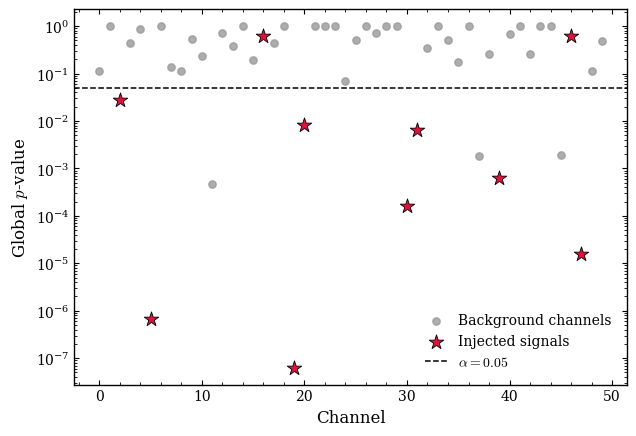

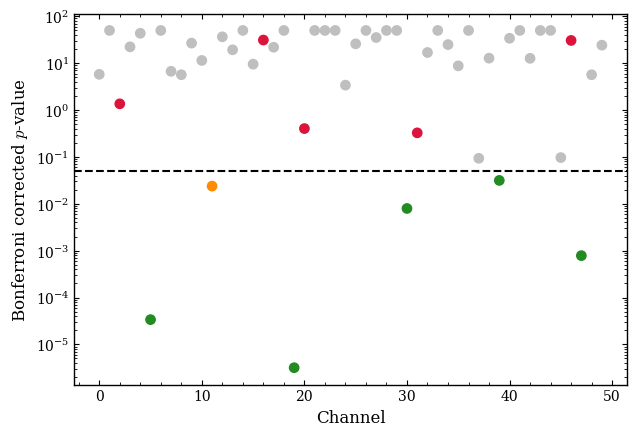

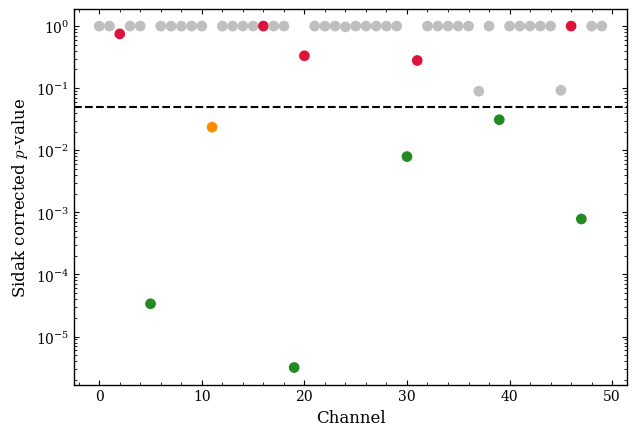

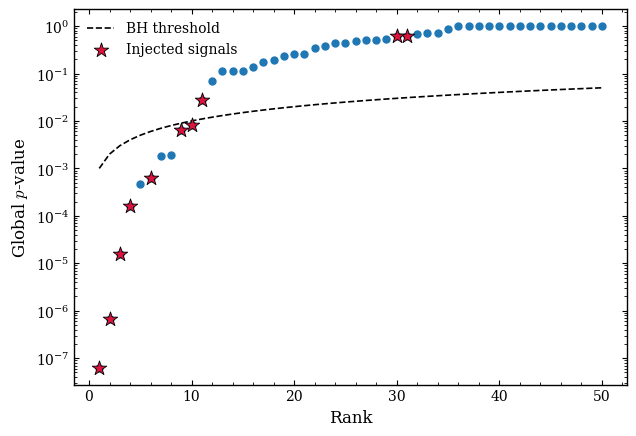

In [20]:
all_channels = np.arange(N_CHANNELS)
bkg_mask = np.ones(N_CHANNELS, dtype=bool)
bkg_mask[sig_channels] = False
p_global_chan = np.clip(np.array(p_global_chan), None, 1.0)

# BH method
p_global_argsorted = np.argsort(p_global_chan)
p_global_sorted = np.sort(p_global_chan)
bh_thresholds = np.arange(1, N_CHANNELS + 1) / N_CHANNELS * 0.05  # FDR level of 5%

ranks = np.arange(1, N_CHANNELS + 1)
rank_of_channel = np.empty(N_CHANNELS, dtype=int)
rank_of_channel[p_global_argsorted] = np.arange(N_CHANNELS)
sig_ranks = rank_of_channel[sig_channels] + 1

# Bonferroni method
p_global_bonferroni = np.clip(p_global_chan * N_CHANNELS, None, 1.0)

# Sidak method
p_global_sidak = 1 - np.power((1 - p_global_chan), N_CHANNELS)

# ------------------------------------------------------------------------------------------
# Plots
# ------------------------------------------------------------------------------------------
# 1) Global p-values for each channel
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(all_channels[bkg_mask],p_global_chan[bkg_mask], s=28, color='0.6', alpha=0.8, label='Background channels')
ax.scatter(sig_channels, p_global_chan[sig_channels], s=120, marker='*', color='crimson', edgecolor='black', linewidth=0.6, zorder=5,label='Injected signals')
ax.axhline(0.05,color='black',ls='--',lw=1.1,label=r'$\alpha = 0.05$')
ax.set_yscale('log')
ax.set_xlabel('Channel')
ax.set_ylabel('Global $p$-value')
#ax.set_ylim(1e-70, 1)
ax.legend(frameon=False, loc='lower right', handlelength=1.6, borderpad=0.6)
fig.savefig(os.path.join(OUT_DIR, 'global_pval_per_channel.pdf'), dpi=300)
fig.tight_layout()

# 2) Bonferroni method
detected = np.where(p_global_bonferroni < 0.05)[0]
tp = np.intersect1d(detected, sig_channels)
fp = np.setdiff1d(detected, sig_channels)
fn = np.setdiff1d(sig_channels, detected)
colors = np.full(N_CHANNELS, '0.75', dtype=object)
colors[tp] = 'forestgreen'
colors[fp] = 'darkorange'
colors[fn] = 'crimson'

fig1, ax1 = plt.subplots(figsize=(6.5,4.5))
ax1.scatter(np.arange(N_CHANNELS), p_global_bonferroni, c=colors, s=45)
ax1.axhline(0.05, ls='--', color='black')
ax1.set_yscale('log')
ax1.set_xlabel('Channel')
ax1.set_ylabel('Bonferroni corrected $p$-value')
fig1.savefig(os.path.join(OUT_DIR, 'bonferroni_corrected_pval.pdf'), dpi=300)
fig1.tight_layout()

# 3) Sidak method
detected = np.where(p_global_sidak < 0.05)[0]
tp = np.intersect1d(detected, sig_channels)
fp = np.setdiff1d(detected, sig_channels)
fn = np.setdiff1d(sig_channels, detected)
colors = np.full(N_CHANNELS, '0.75', dtype=object)
colors[tp] = 'forestgreen'
colors[fp] = 'darkorange'
colors[fn] = 'crimson'

fig2, ax2 = plt.subplots(figsize=(6.5,4.5))
ax2.scatter(np.arange(N_CHANNELS), p_global_sidak, c=colors, s=45)
ax2.axhline(0.05, ls='--', color='black')
ax2.set_yscale('log')
ax2.set_xlabel('Channel')
ax2.set_ylabel('Sidak corrected $p$-value')
#ax2.set_ylim(1e-70, 1)
fig2.savefig(os.path.join(OUT_DIR, 'sidak_corrected_pval.pdf'), dpi=300)
fig2.tight_layout()


# 2) BH method with FDR threshold
fig3, ax3 = plt.subplots(figsize=(6.5, 4.5))
ax3.scatter(ranks, p_global_sorted, s=25, color='C0')
ax3.plot(ranks, bh_thresholds, '--', color='black', lw=1.2, label='BH threshold')
ax3.scatter(sig_ranks, p_global_chan[sig_channels], s=120, marker='*', color='crimson', edgecolor='black', linewidth=0.6, zorder=10, label='Injected signals')
ax3.set_yscale('log')
ax3.set_xlabel('Rank')
ax3.set_ylabel('Global $p$-value')
ax3.legend(frameon=False)
fig3.tight_layout()
fig3.savefig(os.path.join(OUT_DIR, 'bh_corrected_pval.pdf'), dpi=300)

plt.show()